In [ ]:
!pip -q install opensmile librosa soundfile transformers scikit-learn openpyxl seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 26.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.0/75.0 kB 8.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 14.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 31.8 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob, random, warnings, gc, json, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import librosa
import opensmile

from transformers import AutoTokenizer, AutoModel
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, f1_score)
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

METADATA_PATH = '/content/drive/MyDrive/telugu_dataset/TELUGU DATASET/TE/Excel/TELUGU_METADATA.xlsx'
AUDIO_ROOTS = [
    '/content/drive/MyDrive/telugu_dataset',
    '/content/drive/MyDrive/augmented_audios',
    '/content/drive/MyDrive'
]
# Runtime-only outputs. No models/checkpoints are saved.
OUTPUT_DIR = '/content/multimodal_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

LABSE_NAME = 'sentence-transformers/LaBSE'
TEXT_BATCH_SIZE = 16
MAX_TEXT_LENGTH = 128
AUDIO_MAX_SECONDS = 20  # cap very long clips to keep extraction manageable


Mounted at /content/drive
Device: cuda


## Index audio files and load matched text/audio rows

In [ ]:
assert os.path.isfile(METADATA_PATH), f'Metadata workbook not found: {METADATA_PATH}'

audio_index = {}
valid_exts = {'.wav', '.mp3', '.flac', '.ogg', '.m4a'}
for root in AUDIO_ROOTS:
    if os.path.isdir(root):
        for p in glob.iglob(os.path.join(root, '**', '*'), recursive=True):
            if os.path.isfile(p) and Path(p).suffix.lower() in valid_exts:
                # Keep the first match; avoid repeated Drive scanning later.
                audio_index.setdefault(Path(p).stem.strip().lower(), p)
print('Indexed audio files:', len(audio_index))

def find_audio(name):
    stem = Path(str(name).strip()).stem.strip().lower()
    return audio_index.get(stem)

def clean_text(x):
    if pd.isna(x):
        return ''
    return str(x).strip()

xls = pd.ExcelFile(METADATA_PATH)
print('Workbook sheets:', xls.sheet_names)


hate_raw = pd.read_excel(METADATA_PATH, sheet_name='HATE')
nonhate_raw = pd.read_excel(METADATA_PATH, sheet_name='NON HATE')
for frame_name, frame in [('HATE', hate_raw), ('NON HATE', nonhate_raw)]:
    frame.columns = frame.columns.str.strip()
    required = {'TRANSCRIPTION'}
    if not required.issubset(frame.columns):
        raise ValueError(f'{frame_name} sheet must contain TRANSCRIPTION. Found: {frame.columns.tolist()}')

def get_filename(row):
    for col in ['AUDIO FILE NAME', 'Audio File Name', 'FILE NAME', 'File Name']:
        if col in row.index and pd.notna(row[col]) and str(row[col]).strip():
            return str(row[col]).strip()
    return ''

def rows_from_sheet(frame, label, category=None):
    records = []
    for _, row in frame.iterrows():
        text = clean_text(row.get('TRANSCRIPTION', ''))
        audio_name = get_filename(row)
        if not text or not audio_name:
            continue
        audio_path = find_audio(audio_name)
        if audio_path is None:
            continue
        records.append({'audio_name': Path(audio_name).name, 'audio_path': audio_path,
                        'text': text, 'binary_label': int(label),
                        'multi_label': category if category is not None else 'NH'})
    return records

# Binary task: all HATE examples = 1, all NON HATE examples = 0.
records = rows_from_sheet(hate_raw, 1)
records += rows_from_sheet(nonhate_raw, 0, 'NH')

# Multi-class labels follow the earlier text notebook: NH=0, C=1, G=2, R=3, P=4.
# HATE rows use SHORT LABLE; NON HATE rows are NH.
multi_records = []
for rec in records:
    if rec['binary_label'] == 0:
        rec['multi_label'] = 'NH'
    else:
        # Recover category from matching filename in HATE sheet.
        match = hate_raw[hate_raw['AUDIO FILE NAME'].astype(str).str.strip().apply(
            lambda x: Path(x).stem.lower()) == Path(rec['audio_name']).stem.lower()]
        raw = ''
        if len(match) and 'SHORT LABLE' in match.columns:
            raw = clean_text(match.iloc[0]['SHORT LABLE']).upper()
        rec['multi_label'] = raw
    if rec['multi_label'] in {'C','G','R','P','NH'}:
        multi_records.append(rec)

matched_df = pd.DataFrame(multi_records).drop_duplicates(subset=['audio_path']).reset_index(drop=True)
if matched_df.empty:
    raise ValueError('No matched rows found. Check AUDIO FILE NAME values and AUDIO_ROOTS.')
print('Matched audio/text pairs:', len(matched_df))
print('Binary distribution:\n', matched_df.binary_label.value_counts().sort_index())
print('5-class distribution:\n', matched_df.multi_label.value_counts())
display(matched_df.head())


Indexed audio files: 1274
Workbook sheets: ['HATE', 'NON HATE', 'COUNT']
Matched audio/text pairs: 589
Binary distribution:
 binary_label
0    201
1    388
Name: count, dtype: int64
5-class distribution:
 multi_label
NH    201
C     127
G     111
R      82
P      68
Name: count, dtype: int64


,audio_name,audio_path,text,binary_label,multi_label
0,H_TE_001_R_F_001_001,/content/drive/MyDrive/telugu_dataset/TELUGU D...,ఎస్సీలుగా పుట్టాలని ఎవరు కోరుకుంటారు,1,R
1,H_TE_001_R_F_001_002,/content/drive/MyDrive/telugu_dataset/TELUGU D...,ఎవరు మాత్రం SC కులంలో పుట్టాలని కోరుకుంటారు అం...,1,R
2,H_TE_001_R_M_001_003,/content/drive/MyDrive/telugu_dataset/TELUGU D...,ఎవరు మాత్రం SC కులంలో పుట్టాలని కోరుకుంటారు,1,R
3,H_TE_001_R_M_001_004,/content/drive/MyDrive/telugu_dataset/TELUGU D...,ఎవరు మాత్రం SC కులంలో పుట్టాలని కోరుకుంటారు డబ...,1,R
4,H_TE_001_R_M_001_005,/content/drive/MyDrive/telugu_dataset/TELUGU D...,అందరూ రాజుల కులంలో పుడితే రాజ్యాన్ని ఎలచ్చనుకు...,1,R


## Extract OpenSMILE audio features

In [ ]:
smile = opensmile.Smile(
    feature_set=opensmile.FeatureSet.ComParE_2016,
    feature_level=opensmile.FeatureLevel.LowLevelDescriptors
)
AUDIO_FEATURES = ['pcm_zcr_sma', 'pcm_RMSenergy_sma', 'voicingFinalUnclipped_sma'] + [
    f'mfcc_sma[{i}]' for i in range(1, 13)
]

def extract_audio_stats(path):
    try:
        signal, sr = librosa.load(path, sr=None, mono=True, duration=AUDIO_MAX_SECONDS)
        if signal.size == 0:
            raise ValueError('empty audio')
        frame = smile.process_signal(signal, sr).reset_index(drop=True)
        cols = [c for c in AUDIO_FEATURES if c in frame.columns]
        if not cols:
            raise ValueError('OpenSMILE returned no expected features')
        values = {}
        for col in cols:
            arr = pd.to_numeric(frame[col], errors='coerce').dropna().to_numpy(dtype=np.float32)
            if arr.size == 0:
                arr = np.array([0.0], dtype=np.float32)
            values.update({
                f'{col}_mean': float(np.mean(arr)),
                f'{col}_std': float(np.std(arr)),
                f'{col}_min': float(np.min(arr)),
                f'{col}_max': float(np.max(arr)),
                f'{col}_median': float(np.median(arr)),
            })
        return values
    except Exception as e:
        print(f'Audio feature extraction failed: {path} | {e}')
        return None

audio_rows = []
for p in tqdm(matched_df['audio_path'].tolist(), desc='OpenSMILE features'):
    audio_rows.append(extract_audio_stats(p))
valid = np.array([x is not None for x in audio_rows])
matched_df = matched_df.loc[valid].reset_index(drop=True)
audio_rows = [x for x in audio_rows if x is not None]
audio_features = pd.DataFrame(audio_rows).replace([np.inf, -np.inf], np.nan).fillna(0.0)
print('Audio feature matrix:', audio_features.shape, '| matched samples:', len(matched_df))


OpenSMILE features:   0%|          | 0/589 [00:00<?, ?it/s]

Audio feature matrix: (589, 75) | matched samples: 589


## Extract LaBSE text embeddings

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(LABSE_NAME)
text_encoder = AutoModel.from_pretrained(LABSE_NAME).to(DEVICE)
text_encoder.eval()

@torch.no_grad()
def encode_texts(texts, batch_size=TEXT_BATCH_SIZE):
    all_embeddings = []
    for start in tqdm(range(0, len(texts), batch_size), desc='LaBSE embeddings'):
        batch = texts[start:start + batch_size]
        inputs = tokenizer(batch, padding=True, truncation=True,
                           max_length=MAX_TEXT_LENGTH, return_tensors='pt')
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        output = text_encoder(**inputs).last_hidden_state
        mask = inputs['attention_mask'].unsqueeze(-1).float()
        pooled = (output * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
        pooled = torch.nn.functional.normalize(pooled, p=2, dim=1)
        all_embeddings.append(pooled.cpu().numpy().astype(np.float32))
    return np.vstack(all_embeddings)

text_features = encode_texts(matched_df['text'].tolist())
print('Text embedding matrix:', text_features.shape)

del text_encoder, tokenizer
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


config.json:   0%|          | 0.00/804 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/397 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/5.22M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.62M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.88GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

LaBSE embeddings:   0%|          | 0/37 [00:00<?, ?it/s]

Text embedding matrix: (589, 768)


## Shared train/test split and evaluation

In [ ]:
# One split shared by all modalities and both tasks for direct comparability.
indices = np.arange(len(matched_df))
train_idx, test_idx = train_test_split(
    indices, test_size=0.20, random_state=SEED,
    stratify=matched_df['binary_label']
)
A_train, A_test = audio_features.iloc[train_idx].to_numpy(), audio_features.iloc[test_idx].to_numpy()
T_train, T_test = text_features[train_idx], text_features[test_idx]

def build_classifier():
    return make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED)
    )

def score_predictions(y_true, y_pred, class_labels, task, model_name):
    p, r, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=class_labels, average='macro', zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)
    print(f'\n{task} | {model_name}: accuracy={acc:.4f}, macro-F1={f1_macro:.4f}')
    print(classification_report(y_true, y_pred, labels=class_labels, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=class_labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{task} — {model_name}')
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.tight_layout(); plt.show()
    return {'task': task, 'model': model_name, 'accuracy': acc,
            'macro_precision': p, 'macro_recall': r, 'macro_f1': f1_macro,
            'n_test': len(y_true)}, y_pred

all_results, all_predictions = [], {}

## Run binary and five-class experiments

=== BINARY CLASSIFICATION ===

Binary | Audio-only (OpenSMILE): accuracy=0.8475, macro-F1=0.8318
              precision    recall  f1-score   support

           0       0.76      0.80      0.78        40
           1       0.89      0.87      0.88        78

    accuracy                           0.85       118
   macro avg       0.83      0.84      0.83       118
weighted avg       0.85      0.85      0.85       118



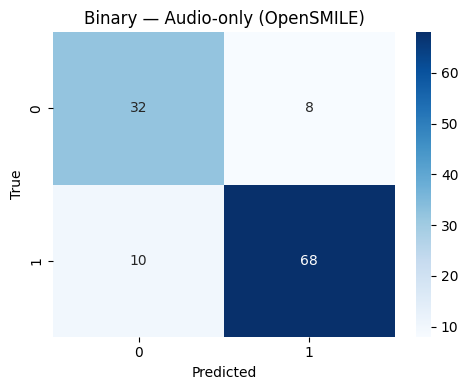


Binary | Text-only (LaBSE): accuracy=0.8729, macro-F1=0.8590
              precision    recall  f1-score   support

           0       0.80      0.82      0.81        40
           1       0.91      0.90      0.90        78

    accuracy                           0.87       118
   macro avg       0.86      0.86      0.86       118
weighted avg       0.87      0.87      0.87       118



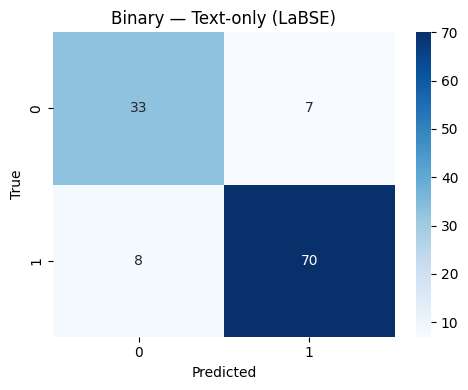


Binary | Early fusion (OpenSMILE + LaBSE): accuracy=0.8983, macro-F1=0.8865
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        40
           1       0.92      0.92      0.92        78

    accuracy                           0.90       118
   macro avg       0.89      0.89      0.89       118
weighted avg       0.90      0.90      0.90       118



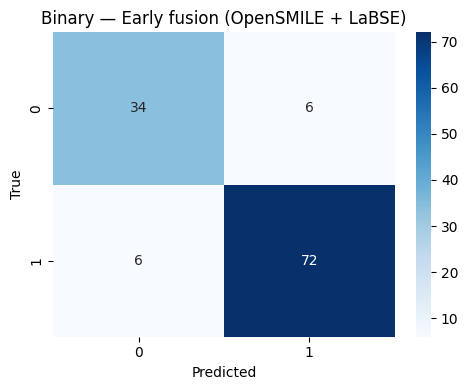


Binary | Late fusion (mean probabilities): accuracy=0.8898, macro-F1=0.8778
              precision    recall  f1-score   support

           0       0.83      0.85      0.84        40
           1       0.92      0.91      0.92        78

    accuracy                           0.89       118
   macro avg       0.88      0.88      0.88       118
weighted avg       0.89      0.89      0.89       118



In [ ]:
def run_task(task, y_all, class_labels):
    y_all = np.asarray(y_all)
    y_train, y_test = y_all[train_idx], y_all[test_idx]
    task_results = {}

    # Audio-only
    audio_clf = build_classifier()
    audio_clf.fit(A_train, y_train)
    pred_a = audio_clf.predict(A_test)
    row, _ = score_predictions(y_test, pred_a, class_labels, task, 'Audio-only (OpenSMILE)')
    all_results.append(row); task_results['Audio-only (OpenSMILE)'] = pred_a

    # Text-only
    text_clf = build_classifier()
    text_clf.fit(T_train, y_train)
    pred_t = text_clf.predict(T_test)
    row, _ = score_predictions(y_test, pred_t, class_labels, task, 'Text-only (LaBSE)')
    all_results.append(row); task_results['Text-only (LaBSE)'] = pred_t

    # Early fusion: concatenate features, scaling is done inside the classifier pipeline.
    Xef_train = np.hstack([A_train, T_train])
    Xef_test = np.hstack([A_test, T_test])
    early_clf = build_classifier()
    early_clf.fit(Xef_train, y_train)
    pred_ef = early_clf.predict(Xef_test)
    row, _ = score_predictions(y_test, pred_ef, class_labels, task, 'Early fusion (OpenSMILE + LaBSE)')
    all_results.append(row); task_results['Early fusion (OpenSMILE + LaBSE)'] = pred_ef

    # Late fusion: average class probabilities from separately trained modality classifiers.
    # Align probability columns to class_labels, which may be non-contiguous in small splits.
    prob_a = audio_clf.predict_proba(A_test)
    prob_t = text_clf.predict_proba(T_test)
    def align_probs(clf, probs, labels):
        aligned = np.zeros((len(probs), len(labels)), dtype=float)
        for j, label in enumerate(clf.classes_):
            if label in labels:
                aligned[:, labels.index(label)] = probs[:, j]
        return aligned
    pa = align_probs(audio_clf, prob_a, list(class_labels))
    pt = align_probs(text_clf, prob_t, list(class_labels))
    pred_lf = np.asarray(class_labels)[((pa + pt) / 2).argmax(axis=1)]
    row, _ = score_predictions(y_test, pred_lf, class_labels, task, 'Late fusion (mean probabilities)')
    all_results.append(row); task_results['Late fusion (mean probabilities)'] = pred_lf

    all_predictions[task] = {'y_true': y_test, **task_results}
    return task_results

binary_names = ['Non-Hate', 'Hate']
multi_names = ['NH', 'C', 'G', 'R', 'P']

print('=== BINARY CLASSIFICATION ===')
binary_preds = run_task('Binary', matched_df['binary_label'].to_numpy(), [0, 1])

print('=== FIVE-CLASS CLASSIFICATION ===')
# Map category names to stable IDs used by the earlier text notebook: NH=0,C=1,G=2,R=3,P=4
multi_map = {'NH': 0, 'C': 1, 'G': 2, 'R': 3, 'P': 4}
y_multi = matched_df['multi_label'].map(multi_map).to_numpy()
multi_preds = run_task('Multiclass', y_multi, [0, 1, 2, 3, 4])

## Compare audio, text, and multimodal results

,task,model,accuracy,macro_precision,macro_recall,macro_f1,n_test
2,Binary,Early fusion (OpenSMILE + LaBSE),0.8983,0.8865,0.8865,0.8865,118
3,Binary,Late fusion (mean probabilities),0.8898,0.8757,0.8801,0.8778,118
1,Binary,Text-only (LaBSE),0.8729,0.8570,0.8612,0.8590,118
0,Binary,Audio-only (OpenSMILE),0.8475,0.8283,0.8359,0.8318,118
7,Multiclass,Late fusion (mean probabilities),0.7966,0.7687,0.7960,0.7798,118
6,Multiclass,Early fusion (OpenSMILE + LaBSE),0.7797,0.7550,0.7925,0.7666,118
5,Multiclass,Text-only (LaBSE),0.7542,0.7320,0.7472,0.7371,118
4,Multiclass,Audio-only (OpenSMILE),0.6017,0.5643,0.6027,0.5699,118


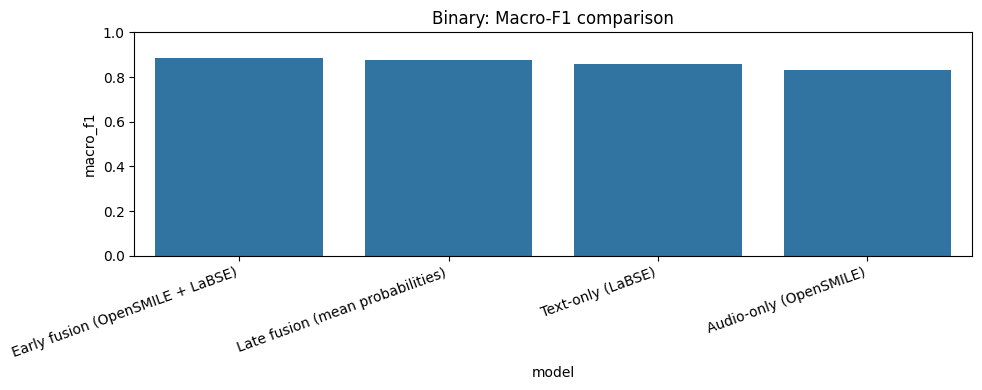

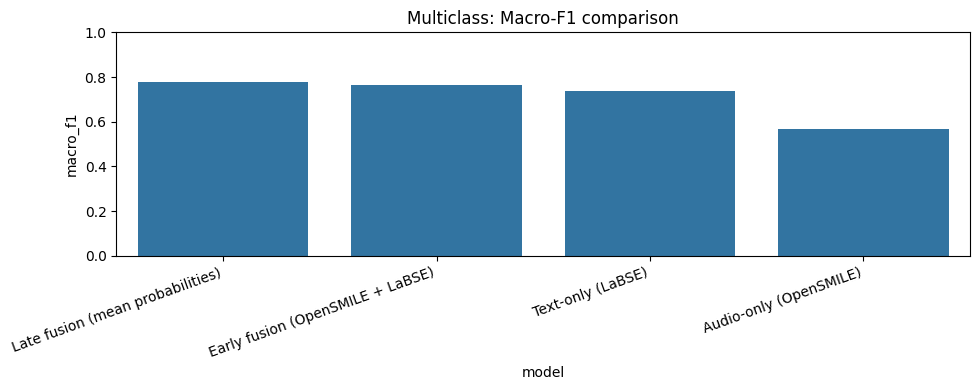

Best model per task by macro-F1:


,task,model,accuracy,macro_f1
2,Binary,Early fusion (OpenSMILE + LaBSE),0.8983,0.8865
7,Multiclass,Late fusion (mean probabilities),0.7966,0.7798


In [ ]:
results_df = pd.DataFrame(all_results).sort_values(['task', 'macro_f1'], ascending=[True, False])
display(results_df.round(4))
results_df.to_csv(os.path.join(OUTPUT_DIR, 'multimodal_comparison.csv'), index=False)

for task in results_df['task'].unique():
    sub = results_df[results_df.task == task].sort_values('macro_f1', ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(data=sub, x='model', y='macro_f1')
    plt.ylim(0, 1); plt.xticks(rotation=20, ha='right')
    plt.title(f'{task}: Macro-F1 comparison')
    plt.tight_layout(); plt.show()

best_rows = results_df.loc[results_df.groupby('task')['macro_f1'].idxmax()]
print('Best model per task by macro-F1:')
display(best_rows[['task', 'model', 'accuracy', 'macro_f1']].round(4))

## Compare against earlier audio-only and text-only notebooks



In [ ]:
# Optional: add metrics copied from previous notebook result tables.
# Values below are from your previously shared results.
previous_results = [
    {'task': 'Binary', 'model': 'OpenSMILE + SVM (audio)', 'accuracy': 0.818182, 'macro_f1': 0.869048},
    {'task': 'Binary', 'model': 'OpenSMILE + Gradient Boosting (audio)', 'accuracy': 0.818182, 'macro_f1': 0.865854},
    {'task': 'Binary', 'model': 'XLS-R + LSTM (audio)', 'accuracy': 0.677686, 'macro_f1': 0.485106},
    {'task': 'Binary', 'model': 'XLS-R + 1D-CNN (audio)', 'accuracy': 0.652893, 'macro_f1': 0.395000},
    {'task': 'Binary', 'model': 'Wav2Vec2 (audio)', 'accuracy': 0.776860, 'macro_f1': 0.762244},
    {'task': 'Binary', 'model': 'AST (audio)', 'accuracy': 0.859504, 'macro_f1': 0.844131},
    {'task': 'Binary', 'model': 'LaBSE (text)', 'accuracy': 0.892562, 'macro_f1': 0.879380},
    {'task': 'Binary', 'model': 'TF-IDF (text)', 'accuracy': 0.851240, 'macro_f1': 0.839286},
    {'task': 'Binary', 'model': 'mBERT (text)', 'accuracy': 0.818182, 'macro_f1': 0.812535},
    {'task': 'Binary', 'model': 'XLM-RoBERTa (text)', 'accuracy': 0.818182, 'macro_f1': 0.811366},

    {'task': 'Multiclass', 'model': 'OpenSMILE + SVM (audio)', 'accuracy': 0.636364, 'macro_f1': 0.585945},
    {'task': 'Multiclass', 'model': 'OpenSMILE + Gradient Boosting (audio)', 'accuracy': 0.595041, 'macro_f1': 0.523362},
    {'task': 'Multiclass', 'model': 'XLS-R + LSTM (audio)', 'accuracy': 0.438017, 'macro_f1': 0.407924},
    {'task': 'Multiclass', 'model': 'XLS-R + 1D-CNN (audio)', 'accuracy': 0.421488, 'macro_f1': 0.312180},
    {'task': 'Multiclass', 'model': 'Wav2Vec2 (audio)', 'accuracy': 0.454545, 'macro_f1': 0.393545},
    {'task': 'Multiclass', 'model': 'AST (audio)', 'accuracy': 0.702479, 'macro_f1': 0.622943},
    {'task': 'Multiclass', 'model': 'LaBSE (text)', 'accuracy': 0.826446, 'macro_f1': 0.792877},
    {'task': 'Multiclass', 'model': 'TF-IDF (text)', 'accuracy': 0.801653, 'macro_f1': 0.775840},
    {'task': 'Multiclass', 'model': 'mBERT (text)', 'accuracy': 0.652893, 'macro_f1': 0.585461},
    {'task': 'Multiclass', 'model': 'XLM-RoBERTa (text)', 'accuracy': 0.702479, 'macro_f1': 0.591579},
]

if previous_results:
    previous_df = pd.DataFrame(previous_results)

    combined = pd.concat([
        results_df[['task', 'model', 'accuracy', 'macro_f1']],
        previous_df[['task', 'model', 'accuracy', 'macro_f1']]
    ], ignore_index=True)

    display(
        combined.sort_values(
            ['task', 'macro_f1'],
            ascending=[True, False]
        ).round(4)
    )

    combined.to_csv(
        os.path.join(OUTPUT_DIR, 'all_modalities_comparison.csv'),
        index=False
    )

    print('Comparison saved:', os.path.join(
        OUTPUT_DIR, 'all_modalities_comparison.csv'
    ))
else:
    print('No previous metrics entered.')
    print('Results saved only in this Colab runtime:', OUTPUT_DIR)

,task,model,accuracy,macro_f1
0,Binary,Early fusion (OpenSMILE + LaBSE),0.8983,0.8865
14,Binary,LaBSE (text),0.8926,0.8794
1,Binary,Late fusion (mean probabilities),0.8898,0.8778
8,Binary,OpenSMILE + SVM (audio),0.8182,0.8690
9,Binary,OpenSMILE + Gradient Boosting (audio),0.8182,0.8659
2,Binary,Text-only (LaBSE),0.8729,0.8590
13,Binary,AST (audio),0.8595,0.8441
15,Binary,TF-IDF (text),0.8512,0.8393
3,Binary,Audio-only (OpenSMILE),0.8475,0.8318
16,Binary,mBERT (text),0.8182,0.8125


Comparison saved: /content/multimodal_results/all_modalities_comparison.csv


## Final Conclusion and Summary

### 1. Overview

This project investigated Telugu hate-speech detection using audio, text, and multimodal approaches. We evaluated traditional audio feature-based models, transformer-based audio models, text representation models, and multimodal fusion strategies. The experiments covered two classification tasks:

- **Binary classification:** Hate vs. Non-Hate.
- **Five-class classification:** Prediction of the five target categories - NH, C, G, R, and P.

The main objective was to determine whether combining audio and textual information improves classification performance compared with using either modality independently.

### 2. Key Experimental Findings

**Binary classification**

The early fusion model combining OpenSMILE audio features with LaBSE text embeddings achieved the best reported binary accuracy of **89.83%** and a macro F1-score of **88.65%**. This was slightly better than LaBSE text-only, which achieved 89.26% accuracy and an 87.94% macro F1-score.

Late fusion, based on averaging the predicted probabilities of the audio and text models, achieved 88.98% accuracy and an 87.78% macro F1-score.

These findings suggest that audio features provide complementary information to textual representations and that combining both modalities can improve binary hate-speech detection.

**Five-class classification**

LaBSE text-only achieved the highest reported multiclass accuracy of **82.64%** and a macro F1-score of **79.29%**. The late fusion model achieved 79.66% accuracy and a 77.98% macro F1-score, while early fusion achieved 77.97% accuracy and a 76.66% macro F1-score.

Although both fusion approaches achieved promising results, neither outperformed LaBSE text-only for the five-class task. This indicates that textual information was more effective for distinguishing the five categories in the current experiments, while adding audio features did not provide a consistent improvement.

### 3. Comparison of Modalities

The results demonstrate that model performance depends on both the input modality and the classification task.

- **Audio modality:** AST achieved the best reported audio-only performance, with 85.95% binary accuracy and 70.25% five-class accuracy.
- **Text modality:** LaBSE was the strongest reported text model, achieving 89.26% binary accuracy and 82.64% five-class accuracy.
- **Multimodal approach:** Early fusion achieved the best reported binary result, while LaBSE text-only remained the strongest approach for five-class classification.

Traditional OpenSMILE-based models also provided useful baselines, while the evaluated XLS-R-based models performed less strongly in these experiments.

### 4. Does Multimodal Learning Help?

The experiments provide evidence that multimodal learning can be beneficial, particularly for binary classification. Early fusion improved binary accuracy over LaBSE text-only by approximately **0.57 percentage points**, with a macro F1-score improvement of approximately **0.71 percentage points**.

However, the results do not establish that multimodal fusion is universally superior. For five-class classification, LaBSE text-only outperformed both early and late fusion. The usefulness of audio information may therefore depend on the classification task, the quality of the learned representations, and the fusion strategy.

### 5. Limitations and Future Improvements

The findings should be interpreted in the context of the dataset size and experimental setup. Before claiming that fusion provides a reliable improvement, all compared models should be evaluated using identical recording-level train, validation, and test partitions. Preprocessing, feature scaling, hyperparameter selection, and fusion weights should be determined without using test-set information.

Future work can investigate learned fusion layers, validation-based probability weighting, class-weighted training, data augmentation, and additional evaluation using per-class precision, recall, F1-scores, and confusion matrices. Repeated stratified group splits or group cross-validation can help determine whether the observed improvements are stable across different data partitions.

### 6. Final Conclusion

In conclusion, this project demonstrates the potential of combining audio and textual information for Telugu hate-speech detection. The early fusion of OpenSMILE features and LaBSE embeddings achieved the best reported binary classification performance, while LaBSE text-only achieved the best reported five-class classification performance.

Therefore, **multimodal fusion was promising for binary detection but did not outperform the text-only baseline for five-class classification in the current experiments**. These results highlight the importance of evaluating individual modalities and fusion strategies separately rather than assuming that combining modalities will always improve performance.

The study provides a useful foundation for further research into robust multimodal Telugu hate-speech detection and the development of systems that use both spoken content and acoustic information.